# Training & Testing Model Klasifikasi Sentimen: Support Vector Machine (SVM)
### Penelitian Publikasi Ilmiah - Analisis Sentimen Usulan Reklasifikasi MSCI Indonesia

Notebook ini memuat seluruh tahapan eksperimen machine learning menggunakan algoritma **Support Vector Machine (SVM)** dengan pipeline bebas data leakage:
1. **Pemuatan Dataset Preprocessing & Labeled:** Mengambil data hasil cleaning, tokenization, stopword removal, stemming, dan sentimen Lexicon.
2. **Train-Test Split (80:20):** Pembagian data teks latih dan uji secara *stratified* sebelum ekstraksi fitur.
3. **Ekstraksi Fitur TF-IDF Bebas Leakage:** `fit_transform` khusus pada data latih, dan `transform only` pada data uji.
4. **Penyeimbangan Data Latih dengan SMOTE:** Mencegah bias kelas mayoritas hanya pada subset data training.
5. **Pelatihan Model & Tuning Hyperparameter:** Eksperimen optimasi kernel (*linear* vs *rbf*) dan parameter regulasi *C* dengan *Grid Search Cross-Validation*.
6. **Pengujian & Evaluasi Performa:** Pengukuran Akurasi, Precision, Recall, F1-Score, dan Confusion Matrix pada data uji alami.
7. **Uji Coba Prediksi Teks Baru:** Fungsi inferensi kalimat tweet baru secara langsung.
8. **Penyimpanan Model & Vectorizer:** Ekspor model SVM dan TF-IDF vectorizer ke direktori `models/`.

In [1]:
import sys
if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8', errors='replace')

import os
import re
import unicodedata
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Scikit-Learn Modules
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    classification_report, 
    confusion_matrix
)

# Imbalanced-Learn (SMOTE)
from imblearn.over_sampling import SMOTE

# Sastrawi untuk inferensi teks baru
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

sns.set_theme(style='whitegrid')
os.makedirs('models', exist_ok=True)
print("[OK] Seluruh pustaka berhasil dimuat!")

[OK] Seluruh pustaka berhasil dimuat!


---  
## 2. Pemuatan Dataset Hasil Preprocessing & Pelabelan

In [2]:
file_path = 'dataset_msci_labeled.csv'
if not os.path.exists(file_path):
    file_path = 'dataset_msci_preprocessed.csv'

df = pd.read_csv(file_path)
print(f"[OK] Dataset berhasil dimuat dari: '{file_path}'")
print(f"Total baris data : {df.shape[0]} tweet")

text_col = 'stemmed_text' if 'stemmed_text' in df.columns else 'clean_text'
df = df.dropna(subset=[text_col, 'sentimen']).reset_index(drop=True)

print(f"\nDistribusi Label Sentimen Asli:")
print(df['sentimen'].value_counts())
print(f"\nPersentase Label Sentimen Asli (%):")
print((df['sentimen'].value_counts(normalize=True) * 100).round(2))
display(df[[text_col, 'sentimen']].head(3))

[OK] Dataset berhasil dimuat dari: 'dataset_msci_labeled.csv'
Total baris data : 1039 tweet

Distribusi Label Sentimen Asli:
sentimen
Negatif    809
Positif    115
Netral     109
Name: count, dtype: int64

Persentase Label Sentimen Asli (%):
sentimen
Negatif    78.32
Positif    11.13
Netral     10.55
Name: proportion, dtype: float64


,stemmed_text,sentimen
0,sentimen msci jadi salah satu faktor turut bay...,Negatif
1,penjelsan benix soal ihsg jatuh ihsg pernah se...,Negatif
2,msci jadi momok ihsg anjlok rp triliun lenyap,Negatif


---  
## 3. Pembagian Data (Train-Test Split: 80% Latih, 20% Uji)
Pembagian dilakukan **sebelum** pembobotan TF-IDF untuk mencegah kebocoran informasi (*data leakage*).

In [3]:
X_raw = df[text_col].astype(str)
y = df['sentimen']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"Jumlah Data Training : {len(y_train)} sampel (80%)")
print(f"Jumlah Data Testing  : {len(y_test)} sampel (20%)")
print("\nDistribusi Kelas pada Data Training (Sebelum SMOTE):")
print(y_train.value_counts())

Jumlah Data Training : 826 sampel (80%)
Jumlah Data Testing  : 207 sampel (20%)

Distribusi Kelas pada Data Training (Sebelum SMOTE):
sentimen
Negatif    647
Positif     92
Netral      87
Name: count, dtype: int64


---  
## 4. Ekstraksi Fitur TF-IDF (Fit pada Train, Transform pada Test)

In [4]:
tfidf = TfidfVectorizer(max_features=1000)

# Fit & Transform pada data latih
X_train = tfidf.fit_transform(X_train_raw).toarray()

# Transform ONLY pada data uji
X_test = tfidf.transform(X_test_raw).toarray()

print("[OK] Pembobotan TF-IDF Selesai!")
print(f" - Matriks Fitur Latih (X_train) : {X_train.shape[0]} baris x {X_train.shape[1]} fitur")
print(f" - Matriks Fitur Uji   (X_test)  : {X_test.shape[0]} baris x {X_test.shape[1]} fitur")

[OK] Pembobotan TF-IDF Selesai!
 - Matriks Fitur Latih (X_train) : 826 baris x 1000 fitur
 - Matriks Fitur Uji   (X_test)  : 207 baris x 1000 fitur


---  
## 5. Penyeimbangan Data Training dengan SMOTE
> **Catatan Ilmiah:** SMOTE hanya diterapkan pada data latih (`X_train`, `y_train`). Data uji (`X_test`, `y_test`) dibiarkan alami.

In [5]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("=== Perbandingan Jumlah Sampel Data Training ===")
print(f"Sebelum SMOTE : {len(y_train)} baris")
print(f"Setelah SMOTE : {len(y_train_res)} baris\n")
print("Distribusi Kelas Data Training Setelah SMOTE:")
print(y_train_res.value_counts())

=== Perbandingan Jumlah Sampel Data Training ===
Sebelum SMOTE : 826 baris
Setelah SMOTE : 1941 baris

Distribusi Kelas Data Training Setelah SMOTE:
sentimen
Negatif    647
Netral     647
Positif    647
Name: count, dtype: int64


---  
## 6. Pelatihan Model Support Vector Machine (SVM) & Hyperparameter Tuning

In [6]:
# Kunci pencarian hanya pada kernel 'linear' dengan variasi parameter C
param_grid = {
    'kernel': ['linear'],
    'C': [0.01, 0.1, 1.0, 5.0, 10.0]
}

print("[INFO] Memulai Grid Search Cross-Validation (5-Fold) untuk SVM Linear...")

# 1. Grid Search pada ruang fitur linear
grid_svm = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=1,
    verbose=1
)

grid_svm.fit(X_train_res, y_train_res)

print("\n[OK] Parameter Terbaik Ditemukan :", grid_svm.best_params_)
print(f"Skor Rata-rata F1-Macro CV     : {grid_svm.best_score_:.4f}")

# 2. Kalibrasi model linear terbaik untuk mengaktifkan predict_proba
print("\n[INFO] Mengalibrasi probabilitas model linear...")
calibrated_svm = CalibratedClassifierCV(grid_svm.best_estimator_, ensemble=False)
calibrated_svm.fit(X_train_res, y_train_res)

# 3. Tetapkan sebagai best_svm
best_svm = calibrated_svm
print("[OK] Pelatihan & Kalibrasi Model SVM Selesai!")

[INFO] Memulai Grid Search Cross-Validation (5-Fold) untuk SVM Linear...
Fitting 5 folds for each of 5 candidates, totalling 25 fits

[OK] Parameter Terbaik Ditemukan : {'C': 5.0, 'kernel': 'linear'}
Skor Rata-rata F1-Macro CV     : 0.9644

[INFO] Mengalibrasi probabilitas model linear...
[OK] Pelatihan & Kalibrasi Model SVM Selesai!


---  
## 7. Pengujian & Evaluasi Performa Model (Testing)

In [7]:
y_pred = best_svm.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("="*55)
print("         RINGKASAN EVALUASI MODEL SVM         ")
print("="*55)
print(f"Akurasi (Accuracy)        : {acc * 100:.2f}%")
print(f"Precision (Macro Average) : {prec_macro * 100:.2f}%")
print(f"Recall (Macro Average)    : {rec_macro * 100:.2f}%")
print(f"F1-Score (Macro Average)  : {f1_macro * 100:.2f}%")
print("-"*55)
print(f"F1-Score (Weighted)       : {f1_weighted * 100:.2f}%")
print("="*55)

print("\nLaporan Klasifikasi Terperinci (Classification Report):")
print(classification_report(y_test, y_pred, zero_division=0))

         RINGKASAN EVALUASI MODEL SVM         
Akurasi (Accuracy)        : 80.68%
Precision (Macro Average) : 62.14%
Recall (Macro Average)    : 58.78%
F1-Score (Macro Average)  : 59.87%
-------------------------------------------------------
F1-Score (Weighted)       : 79.75%

Laporan Klasifikasi Terperinci (Classification Report):
              precision    recall  f1-score   support

     Negatif       0.88      0.91      0.89       162
      Netral       0.52      0.55      0.53        22
     Positif       0.47      0.30      0.37        23

    accuracy                           0.81       207
   macro avg       0.62      0.59      0.60       207
weighted avg       0.79      0.81      0.80       207



---  
## 8. Visualisasi Evaluasi (Confusion Matrix & Grafik Performa)

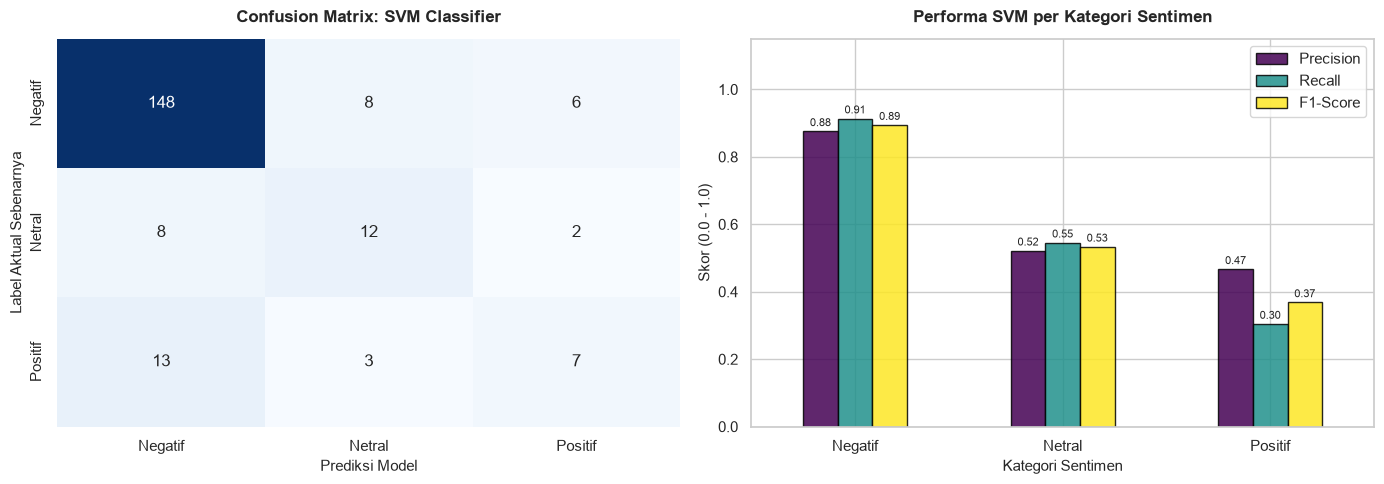

In [8]:
labels_order = ['Negatif', 'Netral', 'Positif']
cm = confusion_matrix(y_test, y_pred, labels=labels_order)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=labels_order, 
    yticklabels=labels_order,
    cbar=False
)
plt.title('Confusion Matrix: SVM Classifier', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Prediksi Model', fontsize=11)
plt.ylabel('Label Aktual Sebenarnya', fontsize=11)

plt.subplot(1, 2, 2)
report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
metrics_df = pd.DataFrame({
    'Precision': [report_dict[c]['precision'] for c in labels_order if c in report_dict],
    'Recall': [report_dict[c]['recall'] for c in labels_order if c in report_dict],
    'F1-Score': [report_dict[c]['f1-score'] for c in labels_order if c in report_dict]
}, index=[c for c in labels_order if c in report_dict])

ax2 = metrics_df.plot(kind='bar', ax=plt.gca(), colormap='viridis', edgecolor='black', alpha=0.85)
plt.title('Performa SVM per Kategori Sentimen', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Kategori Sentimen', fontsize=11)
plt.ylabel('Skor (0.0 - 1.0)', fontsize=11)
plt.ylim(0, 1.15)
plt.legend(loc='upper right', frameon=True)
plt.xticks(rotation=0)

for container in ax2.containers:
    ax2.bar_label(container, fmt='%.2f', fontsize=8, padding=2)

plt.tight_layout()
plt.show()

---  
## 9. Pengujian Kalimat Baru & Probabilitas Keyakinan

In [9]:
stemmer_inf = StemmerFactory().create_stemmer()
stopword_inf = StopWordRemoverFactory().create_stop_word_remover()

def clean_infer(text):
    text = str(text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'[@#]\S+', '', text)
    text = ''.join(c for c in text if not unicodedata.category(c).startswith('S'))
    text = text.encode('ascii', 'ignore').decode('utf-8')
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()

def predict_sentiment_svm(text):
    text_c = clean_infer(text)
    text_stop = stopword_inf.remove(text_c)
    text_stem = " ".join(stemmer_inf.stem(w) for w in text_stop.split())
    
    # Tambahkan .toarray() agar cocok dengan data latih
    vec = tfidf.transform([text_stem]).toarray()
    pred = best_svm.predict(vec)[0]
    
    return pred, text_stem

contoh_kalimat = [
    "Kacau banget kalau sampai beneran turun ke Standalone. Outflow asing bakal makin deras, likuiditas anjlok, nasib porto ritel boncos parah ini.",
    "Peluang serok saham-saham undervalue! Valuasi lagi pada murah karena kepanikan isu MSCI, buat investor jangka panjang ini momentum akumulasi.",
    "ihsg bergerak flat menanti data inflasi dan rilis msci hari ini"
]

print("=== HASIL PREDIKSI TWEET BARU (SVM) ===\n")
for k in contoh_kalimat:
    label, stem_res = predict_sentiment_svm(k)
    print(f"Teks Asli : \"{k}\"")
    print(f"Teks Stem : \"{stem_res}\"")
    print(f"Prediksi  : [{label.upper()}]\n")

=== HASIL PREDIKSI TWEET BARU (SVM) ===

Teks Asli : "Kacau banget kalau sampai beneran turun ke Standalone. Outflow asing bakal makin deras, likuiditas anjlok, nasib porto ritel boncos parah ini."
Teks Stem : "kacau banget kalau beneran turun standalone outflow asing bakal makin deras likuiditas anjlok nasib porto ritel boncos parah"
Prediksi  : [NEGATIF]

Teks Asli : "Peluang serok saham-saham undervalue! Valuasi lagi pada murah karena kepanikan isu MSCI, buat investor jangka panjang ini momentum akumulasi."
Teks Stem : "peluang serok saham saham undervalue valuasi pada murah panik isu msci buat investor jangka panjang momentum akumulasi"
Prediksi  : [POSITIF]

Teks Asli : "ihsg bergerak flat menanti data inflasi dan rilis msci hari ini"
Teks Stem : "ihsg gerak flat nanti data inflasi rilis msci hari"
Prediksi  : [NETRAL]



---  
## 10. Penyimpanan Model SVM & TF-IDF Vectorizer

In [11]:
os.makedirs('models', exist_ok=True)

model_filename = 'models/svm_model.pkl'
vectorizer_filename = 'models/tfidf_vectorizer.pkl'

joblib.dump(best_svm, model_filename)
joblib.dump(tfidf, vectorizer_filename)

print(f"[OK] Model SVM berhasil disimpan ke : '{model_filename}'")
print(f"[OK] TF-IDF Vectorizer berhasil disimpan ke : '{vectorizer_filename}'")

[OK] Model SVM berhasil disimpan ke : 'models/svm_model.pkl'
[OK] TF-IDF Vectorizer berhasil disimpan ke : 'models/tfidf_vectorizer.pkl'
